# Probabilistic FDM — 収束解析 (Matérn-3/2, ドメイン [0, 6])

PDE: $-u''(x) = \sin(2\pi x)$, $\quad u(0) = u(6) = 0$

真の解: $u(x) = \dfrac{\sin(2\pi x)}{(2\pi)^2}$

観測ノイズ: $\Sigma = C\, h^{2\tau}\, I$（境界点はゼロ）

$\tau = 3, 2, 1, 0$ の4パターンで収束レート $\kappa$（$\text{MSE} = O(h^\kappa)$）を比較する。

## 1. パッケージ

In [1]:
using LinearAlgebra
using SpecialFunctions
using Statistics
using Printf
using Plots

## 2. カーネル・観測行列・周辺尤度

In [2]:
# --------------------------------------------------------
# Matérn-3/2 カーネル (ν=1.5 固定, σf 付き)
# --------------------------------------------------------
function matern_kernel(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = abs(x1 - x2)
    r == 0 && return σf^2
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν) / gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_matern(X1, X2; ν=1.5, ℓ=1.0, σf=1.0)
    [matern_kernel(x1, x2; ν=ν, ℓ=ℓ, σf=σf) for x1 in X1, x2 in X2]
end

# --------------------------------------------------------
# 観測行列 H = -Δ_h（負の有限差分ラプラシアン）
# 行順: [bdry_0, int_1, ..., int_{N-1}, bdry_N]
# --------------------------------------------------------
function observation_matrix(n_total, h)
    H = zeros(n_total, n_total)
    H[1, 1]     = 1.0
    H[end, end] = 1.0
    for i in 2:n_total-1
        H[i, i-1] = -1.0 / h^2
        H[i, i]   =  2.0 / h^2
        H[i, i+1] = -1.0 / h^2
    end
    return H
end

# --------------------------------------------------------
# 真の解・右辺・観測ベクトル
# --------------------------------------------------------
u_exact(x) = sin(2π * x) / (2π)^2
f_func(x)  = sin(2π * x)

make_y_train(x_all) = vcat(0.0, f_func.(x_all[2:end-1]), 0.0)

# --------------------------------------------------------
# log 周辺尤度
#   観測ノイズ: σ²_i = C * h^{2τ}（境界点はゼロ）
# --------------------------------------------------------
function log_marginal_matern(X, y; H, h, ν, ℓ, σf, C, τ, jitter=1e-10)
    n          = length(X)
    noise_diag = fill(C * h^(2τ), n)
    noise_diag[1] = noise_diag[end] = 0.0
    Σ = Diagonal(noise_diag)

    K     = kernel_matrix_matern(X, X; ν=ν, ℓ=ℓ, σf=σf)
    K_obs = H * K * H' + Σ + jitter * I

    local L
    try
        L = cholesky(Hermitian(K_obs)).L
    catch
        return -Inf
    end

    α       = L' \ (L \ y)
    logdetK = 2sum(log.(diag(L)))
    return -0.5*(y'*α) - 0.5*logdetK - 0.5*n*log(2π)
end

log_marginal_matern (generic function with 1 method)

## 3. 実験設定

In [4]:
# ============================================================
# 基本設定
# ============================================================
ν_fixed    = 1.5
domain_end = 6.0   # ドメイン [0, 6]
τ_list     = [3, 2, 1, 0]

# 理論収束レート (ν=1.5 Matérn, Probabilistic FDM)
κ_theory = Dict(3 => 4.0, 2 => 4.0, 1 => 3.0, 0 => 1.0)

# --------------------------------------------------------
# h の列: h = 6/K, K は 6 の約数・倍数を選んで等比的に並べる
#   K=15  → h=0.400  (dt=0.4 の基準点)
#   K=20  → h=0.300
#   K=24  → h=0.250
#   K=30  → h=0.200
#   K=40  → h=0.150
#   K=60  → h=0.100
#   K=100 → h=0.060
#   K=150 → h=0.040
# --------------------------------------------------------
K_list = [15, 20, 24, 30, 40, 50, 60, 80, 100, 120, 150]
h_list = domain_end ./ K_list

println("h_list = ", round.(h_list; sigdigits=4))

# --------------------------------------------------------
# ハイパーパラメータ探索グリッド
#   Python での事前解析より有効範囲を絞り込み済み
# --------------------------------------------------------
ℓ_grid  = 10 .^ range(-1, 1, length=10)   # 0.1 〜 10
σf_grid = 10 .^ range(-2, 0, length=10)   # 0.01 〜 1.0
C_grid  = 10 .^ range(-3, 2, length=10)   # 1e-3 〜 1e2

h_list = [0.4, 0.3, 0.25, 0.2, 0.15, 0.12, 0.1, 0.075, 0.06, 0.05, 0.04]


10-element Vector{Float64}:
   0.001
   0.003593813663804626
   0.01291549665014884
   0.046415888336127795
   0.16681005372000587
   0.599484250318941
   2.154434690031884
   7.742636826811269
  27.825594022071243
 100.0

## 4. 収束実験: τ = 3, 2, 1, 0

In [5]:
results = Dict{Int, NamedTuple}()

for τ in τ_list
    println("\n", "="^22, " τ = $τ ", "="^22)

    bias2_list = Float64[]
    var_list   = Float64[]
    mse_list   = Float64[]

    for h in h_list
        X       = collect(0.0:h:domain_end)
        N       = length(X)
        H_h     = observation_matrix(N, h)
        y_train = make_y_train(X)
        u_true  = u_exact.(X)

        # ---- グリッドサーチ (log 周辺尤度最大化) ----
        best_score = -Inf
        best_ℓ, best_σf, best_C = ℓ_grid[1], σf_grid[1], C_grid[1]

        for ℓ in ℓ_grid, σf in σf_grid, C in C_grid
            s = log_marginal_matern(
                X, y_train; H=H_h, h=h,
                ν=ν_fixed, ℓ=ℓ, σf=σf, C=C, τ=τ
            )
            if s > best_score
                best_score = s
                best_ℓ, best_σf, best_C = ℓ, σf, C
            end
        end

        # ---- 事後分布 ----
        noise_diag          = fill(best_C * h^(2τ), N)
        noise_diag[1]       = noise_diag[end] = 0.0
        K_prior = kernel_matrix_matern(X, X; ν=ν_fixed, ℓ=best_ℓ, σf=best_σf)
        A_mat   = H_h * K_prior * H_h' + Diagonal(noise_diag) + 1e-10*I

        α      = A_mat \ y_train
        μ_post = K_prior * H_h' * α
        K_post = K_prior - K_prior * H_h' * (A_mat \ (H_h * K_prior))

        bias2    = mean((μ_post .- u_true).^2)
        var_term = tr(K_post) / N
        mse      = bias2 + var_term

        push!(bias2_list, bias2)
        push!(var_list,   var_term)
        push!(mse_list,   mse)

        K_val = round(Int, domain_end / h)
        @printf("  h=%.4f (K=%3d): ℓ=%4.2f, σf=%.4f, C=%.4f | Bias²=%8.3e  Var=%8.3e  MSE=%8.3e\n",
            h, K_val, best_ℓ, best_σf, best_C, bias2, var_term, mse)
    end

    # ---- 収束レート推定 (log-log 最小二乗) ----
    log_h   = log10.(h_list)
    log_mse = log10.(mse_list)
    lh_c    = log_h  .- mean(log_h)
    lm_c    = log_mse .- mean(log_mse)
    κ_est   = sum(lh_c .* lm_c) / sum(lh_c .^ 2)

    @printf("  → 推定 κ = %.2f  (理論 κ = %.1f)\n", κ_est, κ_theory[τ])

    results[τ] = (
        h      = h_list,
        bias2  = bias2_list,
        var    = var_list,
        mse    = mse_list,
        κ_est  = κ_est,
    )
end


====================== τ = 3 ======================
  h=0.4000 (K= 15): ℓ=0.10, σf=0.0278, C=0.0010 | Bias²=1.673e-04  Var=3.502e-06  MSE=1.708e-04
  h=0.3000 (K= 20): ℓ=0.10, σf=0.0278, C=0.0010 | Bias²=3.897e-05  Var=4.977e-07  MSE=3.947e-05
  h=0.2500 (K= 24): ℓ=0.17, σf=0.0278, C=0.0010 | Bias²=1.682e-05  Var=1.410e-07  MSE=1.696e-05
  h=0.2000 (K= 30): ℓ=0.28, σf=0.0278, C=0.0010 | Bias²=6.320e-06  Var=2.992e-08  MSE=6.350e-06
  h=0.1500 (K= 40): ℓ=0.46, σf=0.0278, C=0.0010 | Bias²=1.876e-06  Var=4.109e-09  MSE=1.881e-06
  h=0.1200 (K= 50): ℓ=0.77, σf=0.0464, C=0.0010 | Bias²=7.475e-07  Var=9.395e-10  MSE=7.485e-07
  h=0.1000 (K= 60): ℓ=1.29, σf=0.0774, C=0.0010 | Bias²=3.554e-07  Var=3.271e-10  MSE=3.557e-07
  h=0.0750 (K= 80): ℓ=1.29, σf=0.0774, C=0.0010 | Bias²=1.110e-07  Var=1.165e-10  MSE=1.111e-07
  h=0.0600 (K=100): ℓ=2.15, σf=0.1292, C=0.0010 | Bias²=4.519e-08  Var=8.791e-11  MSE=4.528e-08
  h=0.0500 (K=120): ℓ=2.15, σf=0.1292, C=0.0010 | Bias²=2.174e-08  Var=8.071e-11  M

## 5. 収束プロット（4パネル）

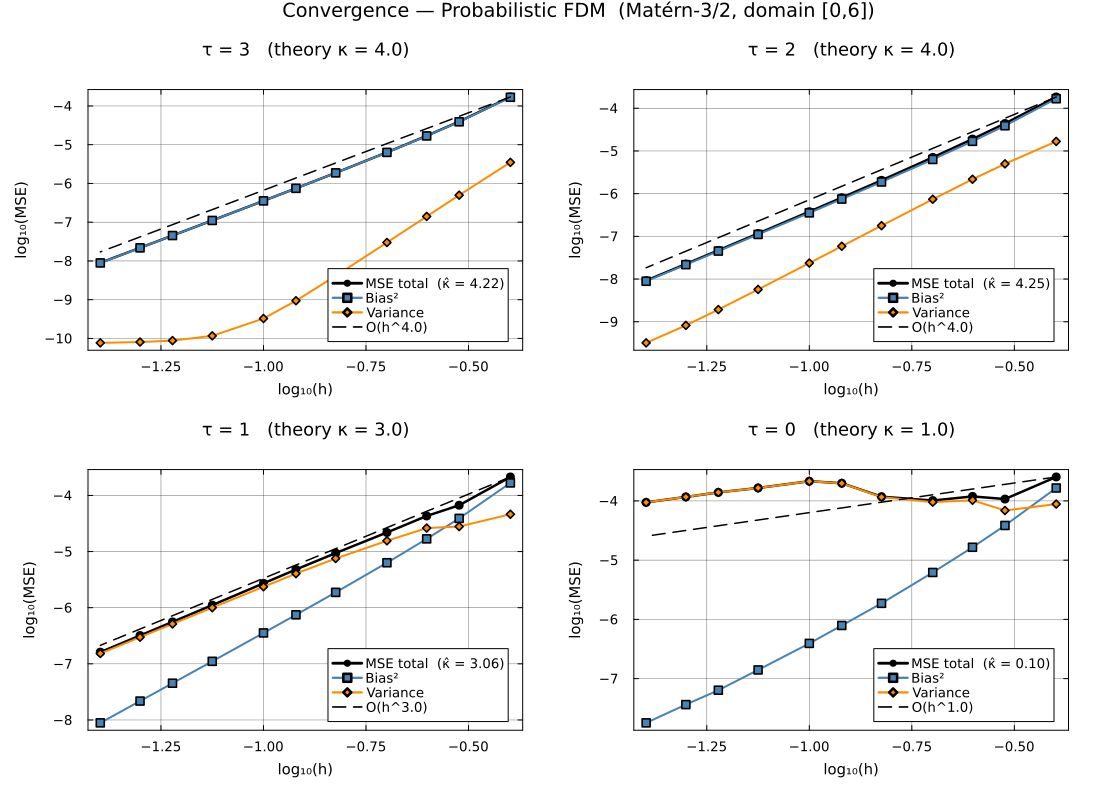

Saved: matern_convergence_domain6.png


In [6]:
plots_list = []

for τ in τ_list
    r   = results[τ]
    κ   = κ_theory[τ]
    lh  = log10.(r.h)

    # 理論参照線: MSE の最初の点を通る傾き κ の直線
    ref_line = log10(r.mse[1]) .+ κ .* (lh .- lh[1])

    κ_str = @sprintf("%.2f", r.κ_est)

    p = plot(
        lh, log10.(r.mse);
        marker=:circle, markersize=5, lw=2.5, color=:black,
        label="MSE total  (κ̂ = $κ_str)",
        xlabel="log₁₀(h)", ylabel="log₁₀(MSE)",
        title="τ = $τ   (theory κ = $κ)",
        legend=:bottomright,
        titlefontsize=12, legendfontsize=9,
        guidefontsize=10, tickfontsize=9,
        grid=true, gridalpha=0.3, framestyle=:box,
    )
    plot!(p, lh, log10.(r.bias2);
        marker=:square, markersize=4, lw=2,
        color=:steelblue, label="Bias²")
    plot!(p, lh, log10.(r.var);
        marker=:diamond, markersize=4, lw=2,
        color=:darkorange, label="Variance")
    plot!(p, lh, ref_line;
        lw=1.5, ls=:dash, color=:black,
        label="O(h^$(κ))")

    push!(plots_list, p)
end

fig = plot(
    plots_list...;
    layout = (2, 2),
    size   = (1100, 800),
    margin = 6Plots.mm,
    plot_title = "Convergence — Probabilistic FDM  (Matérn-3/2, domain [0,6])",
    plot_titlefontsize = 13,
)
display(fig)
savefig(fig, "matern_convergence_domain6.png")
println("Saved: matern_convergence_domain6.png")

## 6. 結果サマリー

In [7]:
println("\n", "="^50)
println("  τ   |  κ_theory  |  κ_est")
println("-"^50)
for τ in τ_list
    @printf("  %d   |    %.1f     |   %.2f\n", τ, κ_theory[τ], results[τ].κ_est)
end
println("="^50)


  τ   |  κ_theory  |  κ_est
--------------------------------------------------
  3   |    4.0     |   4.22
  2   |    4.0     |   4.25
  1   |    3.0     |   3.06
  0   |    1.0     |   0.10
